# Clinical Trial Disease Category Classification Using NLP and Machine Learning
End-to-end walk-through: CSV ➜ DataFrame ➜ cleaning ➜ text preprocessing (tokenization, stop words, lemmatization) ➜ TF-IDF ➜ model comparison ➜ evaluation ➜ insights.

All logic lives in the `src/` package, so this notebook, `run_pipeline.py` and the Streamlit app share exactly the same code. Model tuning (≈10 min) is run by `python run_pipeline.py`; here we re-run the data steps and load the saved model and results.

In [1]:
import sys, json, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, joblib
from IPython.display import Image, display
from src import config as C, preprocessing, features, text_processing as tp
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

## 1. Data collection — CSV ➜ pandas DataFrame

In [2]:
raw = preprocessing.load_raw()
print(raw.shape)
raw.head(3)

(60337, 16)


,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
0,breast cancer,NCT03676114,Effect of Perioperative Low Dose Ketamine on Postoperative Recovery in Patients Undergoing Breast Cancer Surgery,Effect of Perioperative Low Dose Ketamine on Postoperative Recovery in Patients Undergoing Breast Cancer Surgery,"Breast cancer patients often have perioperative emotional disorders such as anxiety and depression, which can lead t...",Breast Cancer,ketamine | Normal saline,UNKNOWN,INTERVENTIONAL,PHASE4,FEMALE,20 Years,65 Years,False,Inclusion Criteria:\n\n1. American Society of Anesthesiologists Grade I-II\n2. Patients undergoing elective breast c...,https://clinicaltrials.gov/study/NCT03676114
1,breast cancer,NCT02941614,Implementing Systematic Distress Screening in Breast Cancer,Implementing Systematic Distress Screening in Breast Cancer,Many breast cancer patients experience psychological distress during their cancer care journey. There are effective ...,Breast Cancer,Distress screening,COMPLETED,OBSERVATIONAL,NaN,ALL,18 Years,NaN,False,"Inclusion Criteria:\n\n* Newly diagnosed with initial breast cancer, any stage, any histology type\n* Kaiser Permane...",https://clinicaltrials.gov/study/NCT02941614
2,breast cancer,NCT04509063,Investigating Public Enthusiasm for Mammography Screening in Denmark,Investigating Public Enthusiasm for Mammography Screening in Denmark,"Based on an American study by Scherer et al., it is hypothesized that some women will make irrational choices regard...",Breast Neoplasm Female | Mammography Screening | Decision Making | Information Seeking Behavior,Information about hypothetical mammography screening without benefits,COMPLETED,INTERVENTIONAL,NaN,FEMALE,44 Years,49 Years,True,Inclusion Criteria:\n\n* Residence: Central Denmark Region\n\nExclusion Criteria:\n\n\-,https://clinicaltrials.gov/study/NCT04509063


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 60337 entries, 0 to 60336
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   source_condition_query  60337 non-null  str   
 1   nct_id                  60337 non-null  str   
 2   title                   60337 non-null  str   
 3   official_title          59551 non-null  str   
 4   brief_summary           60337 non-null  str   
 5   conditions              60336 non-null  str   
 6   interventions           54276 non-null  str   
 7   overall_status          60337 non-null  str   
 8   study_type              60337 non-null  str   
 9   phase                   23336 non-null  str   
 10  sex                     60304 non-null  str   
 11  minimum_age             57121 non-null  str   
 12  maximum_age             28400 non-null  str   
 13  healthy_volunteers      58857 non-null  string
 14  eligibility_criteria    60326 non-null  str   
 15  clinicaltrial

In [4]:
preprocessing.profile(raw)

,dtype,missing,missing_pct,unique
source_condition_query,str,0,0.00,8
nct_id,str,0,0.00,60337
title,str,0,0.00,60191
official_title,str,786,1.30,59272
brief_summary,str,0,0.00,60064
conditions,str,1,0.00,26460
interventions,str,6061,10.05,46807
overall_status,str,0,0.00,13
study_type,str,0,0.00,3
phase,str,37001,61.32,7


The NLP input is **`brief_summary`** (no missing values). The disease-category label comes from **`source_condition_query`** — the condition each trial was retrieved for:

In [5]:
raw.source_condition_query.value_counts()

source_condition_query
breast cancer                            16301
type 2 diabetes                          11467
covid-19                                 10153
anxiety                                   9286
chronic obstructive pulmonary disease     6181
rheumatoid arthritis                      3637
glaucoma                                  2173
sickle cell anemia                        1139
Name: count, dtype: int64

## 2. Data cleaning — missing values, duplicates, types, label encoding
* trailing whitespace stripped, empty strings treated as missing
* duplicates checked on full rows, `nct_id` and **summary text**. Identical summaries with *different* labels are ambiguous and are dropped; repeated summaries with the same label keep one copy (this also prevents the same text landing in both train and test)
* missing values: `official_title` ← `title`, `phase` ← *Not Applicable* (observational / device studies), `interventions`/`eligibility_criteria` ← *Not specified*, `sex` ← mode, `healthy_volunteers` ← *Unknown*
* ages converted to numeric years; a missing maximum age means *no upper limit* and is flagged rather than imputed
* label encoded: readable `disease_category` + integer `label_id`

In [6]:
clean, clog = preprocessing.clean(raw)
{k: v for k, v in clog.items() if k not in ('missing_by_column_raw',)}

{'raw_rows': 60337,
 'raw_columns': 16,
 'missing_cells_raw': 80526,
 'dropped_missing_summary_or_label': 0,
 'dropped_exact_duplicate_rows': 0,
 'dropped_duplicate_nct_id': 0,
 'dropped_summaries_with_conflicting_labels': 30,
 'dropped_duplicate_summaries_same_label': 262,
 'dropped_unknown_label': 0,
 'rows_after_cleaning': 60045,
 'missing_cells_after_cleaning_excl_max_age': 0,
 'class_counts': {'Breast Cancer': 16260,
  'Type 2 Diabetes': 11388,
  'COVID-19': 10100,
  'Anxiety': 9259,
  'COPD': 6137,
  'Rheumatoid Arthritis': 3615,
  'Glaucoma': 2150,
  'Sickle Cell Anemia': 1136}}

In [7]:
print('missing after cleaning:')
clean.isna().sum()[lambda s: s > 0]

missing after cleaning:


max_age_years    31769
dtype: int64

## 3. Text preprocessing & NLP operations
Steps: **normalise** (ASCII, lowercase, URLs, unify *COVID-19* spellings) ➜ **remove punctuation & special characters** ➜ **tokenize** ➜ **remove stop words** (English + clinical boiler-plate such as *study, patient, trial*) ➜ **lemmatize** (NLTK WordNet).

In [8]:
example = clean.brief_summary.iloc[0]
steps = tp.preprocess_steps(example)
for k in ['normalized', 'cleaned']: print(f'{k}:', steps[k][:400], '\n')
for k in ['tokens', 'without_stopwords', 'lemmas']: print(f'{k} ({len(steps[k])}):', steps[k][:40], '\n')

normalized: breast cancer patients often have perioperative emotional disorders such as anxiety and depression, which can lead to poor quality of recovery.this study aims to determine whether ketamine could improve the quality of recovery in breast cancer patients. meanwhile, it will show if ketamine could improve anxiety, depression, postoperative pain and fatigue.this trial also will bring great concerns on 

cleaned: breast cancer patients often have perioperative emotional disorders such as anxiety and depression which can lead to poor quality of recovery this study aims to determine whether ketamine could improve the quality of recovery in breast cancer patients meanwhile it will show if ketamine could improve anxiety depression postoperative pain and fatigue this trial also will bring great concerns on pati 

tokens (74): ['breast', 'cancer', 'patients', 'often', 'have', 'perioperative', 'emotional', 'disorders', 'such', 'as', 'anxiety', 'and', 'depression', 'which', 'can', 'lead

In [9]:
feat = features.add_nlp_features(clean)
feat, n_empty = features.drop_empty_texts(feat)
print('dropped (fewer than 3 tokens after cleaning):', n_empty, '| final rows:', len(feat))
feat[['brief_summary', 'clean_text', 'summary_word_count', 'clean_token_count', 'lexical_diversity', 'mentions_own_disease']].head()

dropped (fewer than 3 tokens after cleaning): 21 | final rows: 60024


,brief_summary,clean_text,summary_word_count,clean_token_count,lexical_diversity,mentions_own_disease
0,"Breast cancer patients often have perioperative emotional disorders such as anxiety and depression, which can lead t...",breast cancer perioperative emotional disorder anxiety depression lead poor quality recovery ketamine improve qualit...,72,35,0.714,True
1,Many breast cancer patients experience psychological distress during their cancer care journey. There are effective ...,breast cancer experience psychological distress cancer care journey effective treatment breast cancer experience dis...,292,145,0.524,True
2,"Based on an American study by Scherer et al., it is hypothesized that some women will make irrational choices regard...",american scherer woman make irrational choice regard participation mammography screen estimate prevalence danish wom...,52,21,0.810,False
3,Compare the effect of ropivacaine versus placebo pectoral nerve block (Pecs 1 and 2) on acute pain after tumorectomy...,ropivacaine placebo pectoral nerve block pecs acute pain tumorectomy plus sentinel lymph node dissection surgery,28,15,1.000,False
4,"Phase 1 dose escalation and expansion study of CLSP-1025, a first-in-class HLA-A\*02:01 specific T cell engager (TCE...",phase dose escalation expansion clsp-1025 first-in-class hla-a specific cell engager tce target solid tumor harbor p...,26,18,1.000,True


## 4. Exploratory data analysis
Figures are produced by `src/eda.py`; tables are in `reports/eda_tables/`.

In [10]:
pd.read_csv(C.TABLES_DIR / 'category_distribution.csv')

,disease_category,trials,pct
0,Breast Cancer,16253,27.08
1,Type 2 Diabetes,11385,18.97
2,COVID-19,10099,16.82
3,Anxiety,9256,15.42
4,COPD,6135,10.22
5,Rheumatoid Arthritis,3612,6.02
6,Glaucoma,2148,3.58
7,Sickle Cell Anemia,1136,1.89


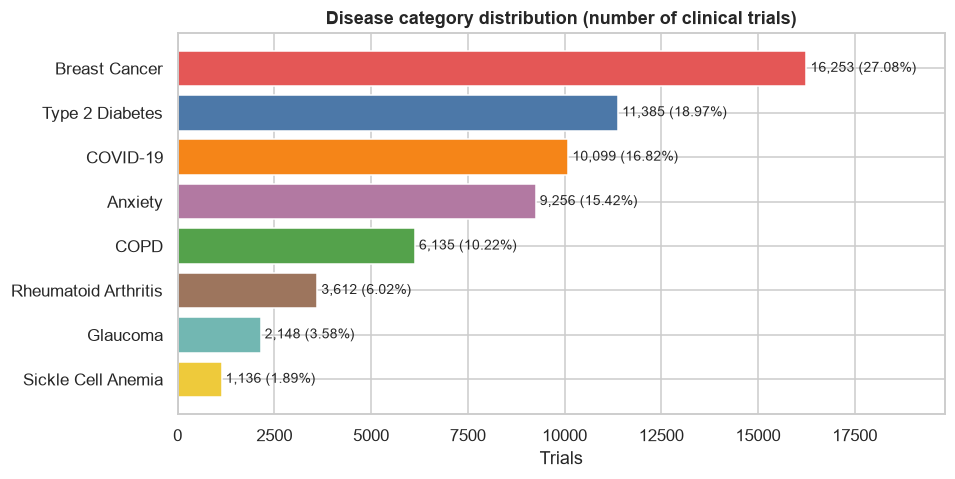

In [11]:
display(Image(C.FIGURES_DIR / 'eda_01_category_distribution.png'))

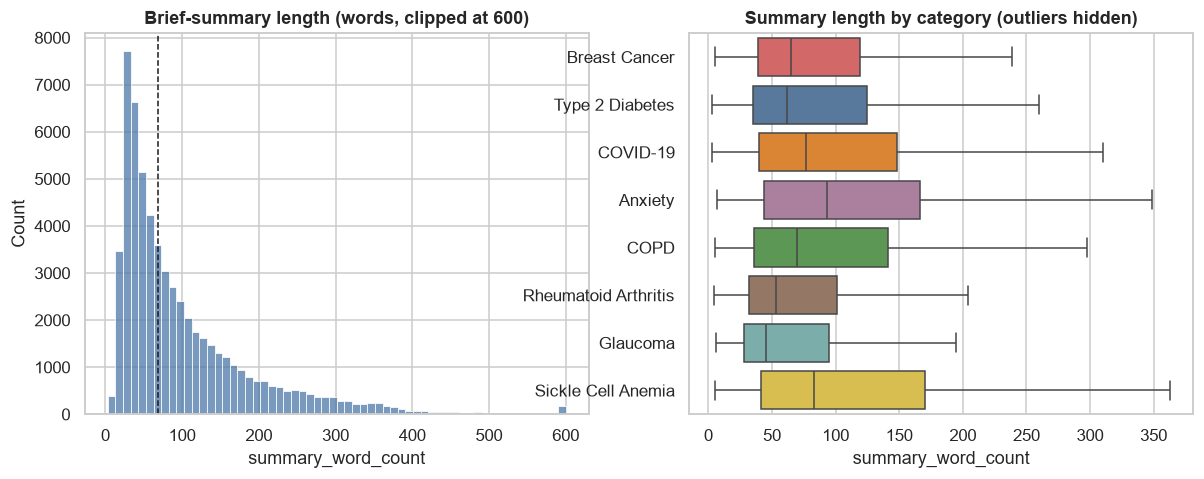

,disease_category,summary_word_count_mean,summary_word_count_median,clean_token_count_mean,clean_token_count_median,lexical_diversity_mean,lexical_diversity_median
0,Breast Cancer,94.94,65.0,47.34,33.0,0.80,0.81
1,Type 2 Diabetes,96.60,62.0,46.51,29.0,0.82,0.83
2,COVID-19,111.03,77.0,54.11,37.0,0.82,0.82
3,Anxiety,121.30,93.0,59.55,45.0,0.78,0.78
4,COPD,103.78,70.0,50.88,34.0,0.82,0.82
5,Rheumatoid Arthritis,84.32,53.0,39.95,25.0,0.85,0.87
6,Glaucoma,77.68,45.0,37.70,22.0,0.85,0.87
7,Sickle Cell Anemia,120.02,83.0,58.77,41.0,0.79,0.79


In [12]:
display(Image(C.FIGURES_DIR / 'eda_02_summary_length.png'))
pd.read_csv(C.TABLES_DIR / 'summary_length_by_category.csv')

### Most common medical terms and keywords

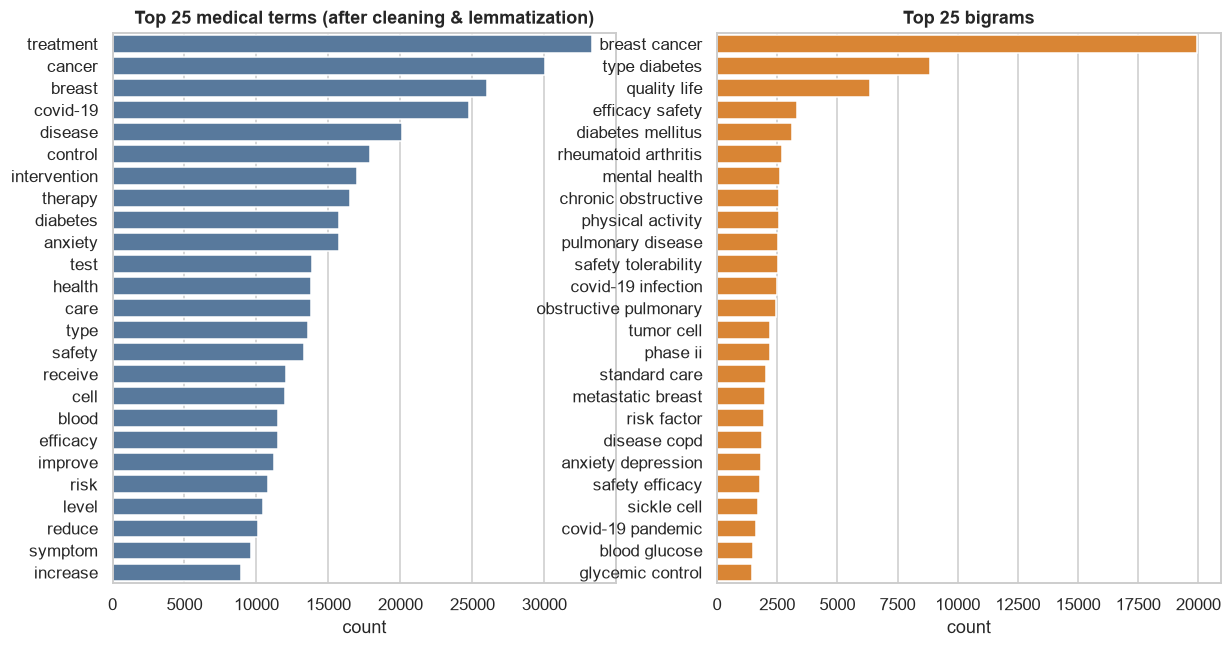

In [13]:
display(Image(C.FIGURES_DIR / 'eda_03_top_terms_bigrams.png'))

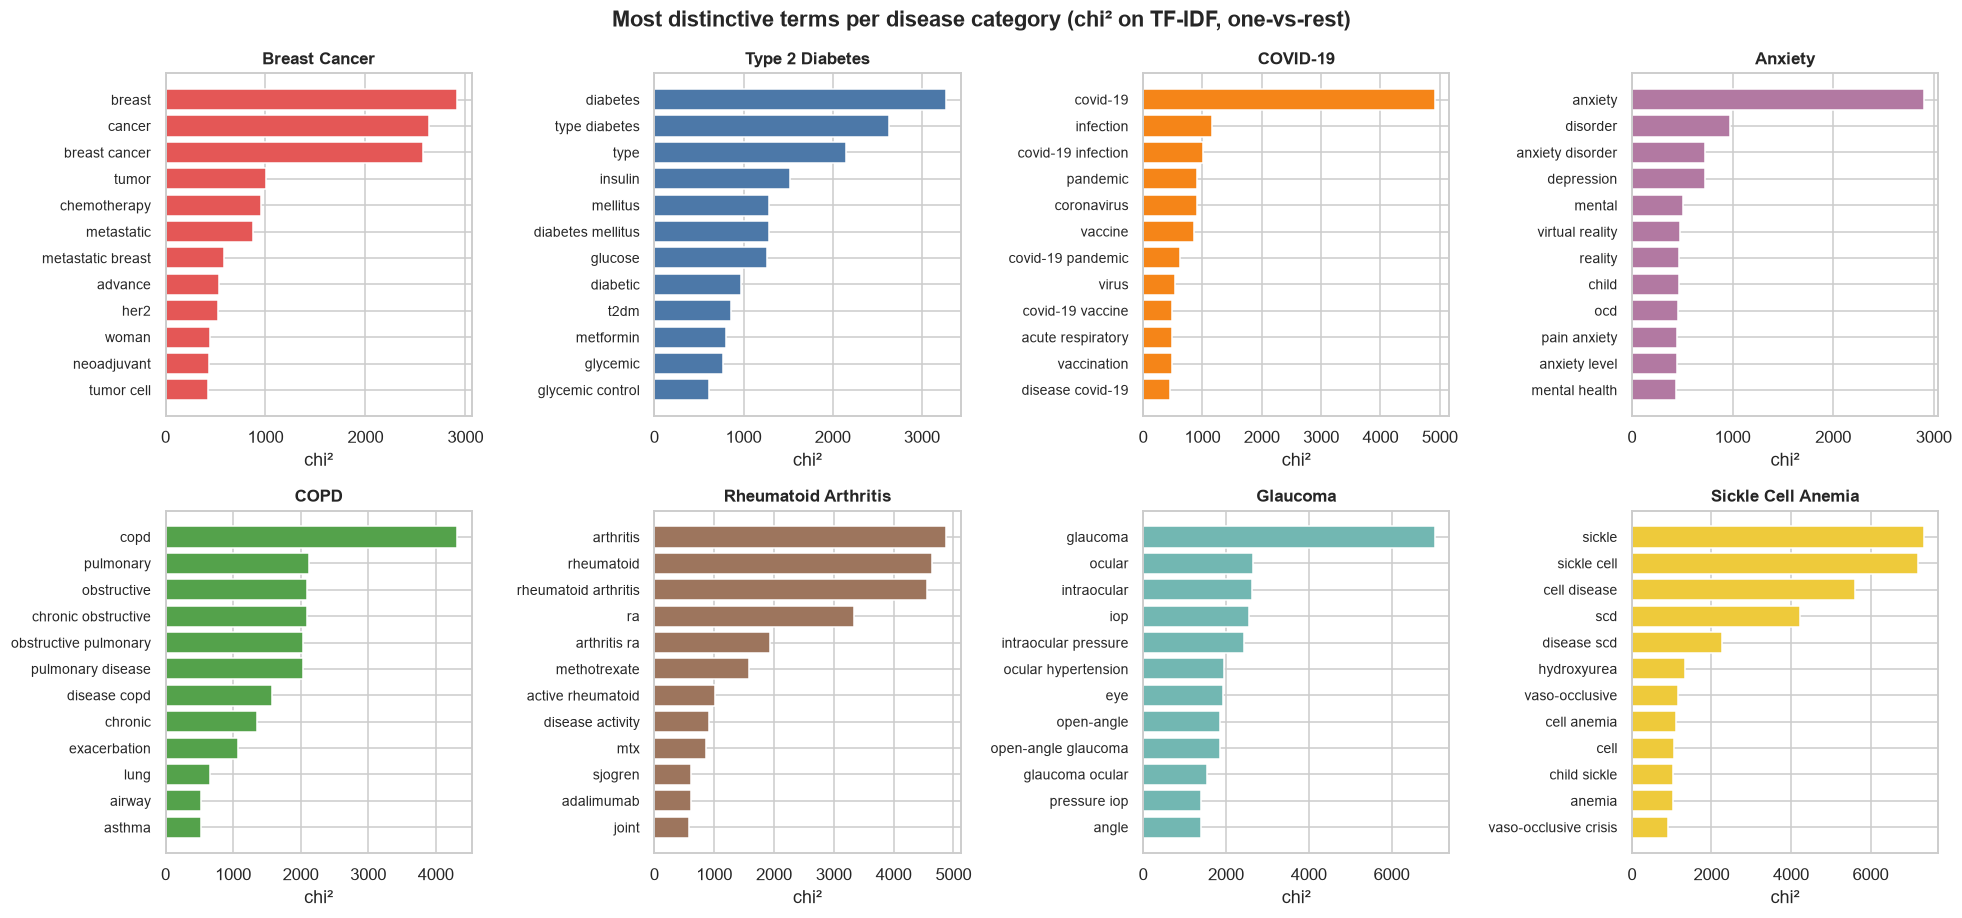

In [14]:
display(Image(C.FIGURES_DIR / 'eda_04_distinctive_terms.png'))

### Trial design patterns by disease category

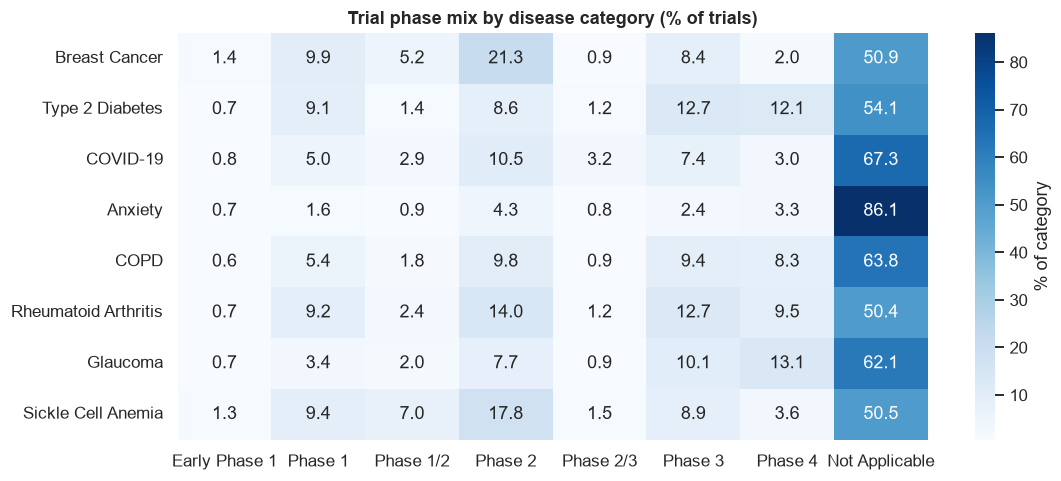

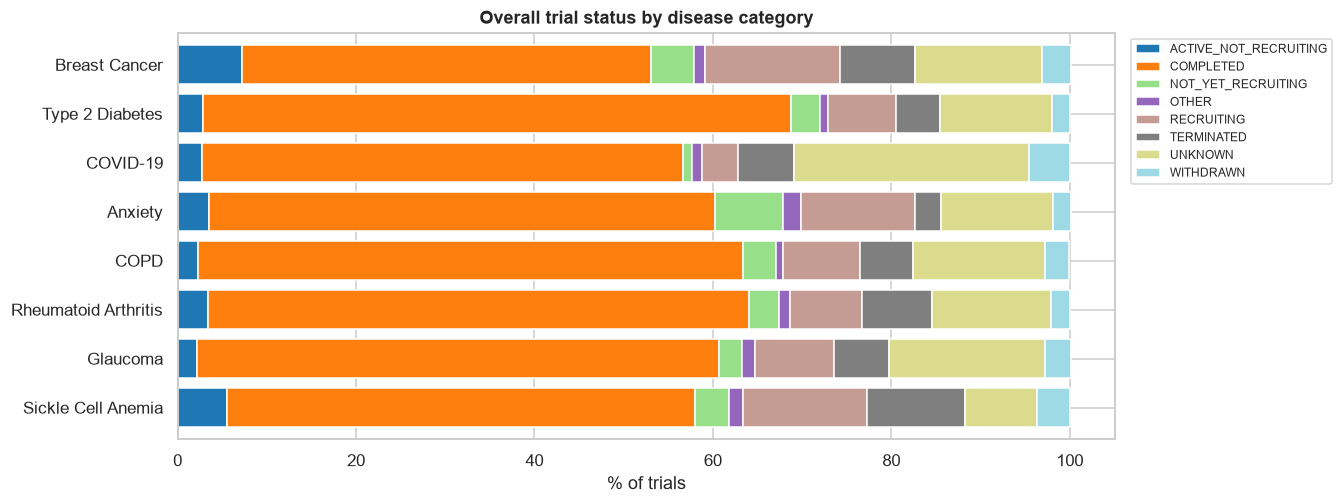

In [15]:
display(Image(C.FIGURES_DIR / 'eda_05_phase_by_category.png'))
display(Image(C.FIGURES_DIR / 'eda_06_status_by_category.png'))

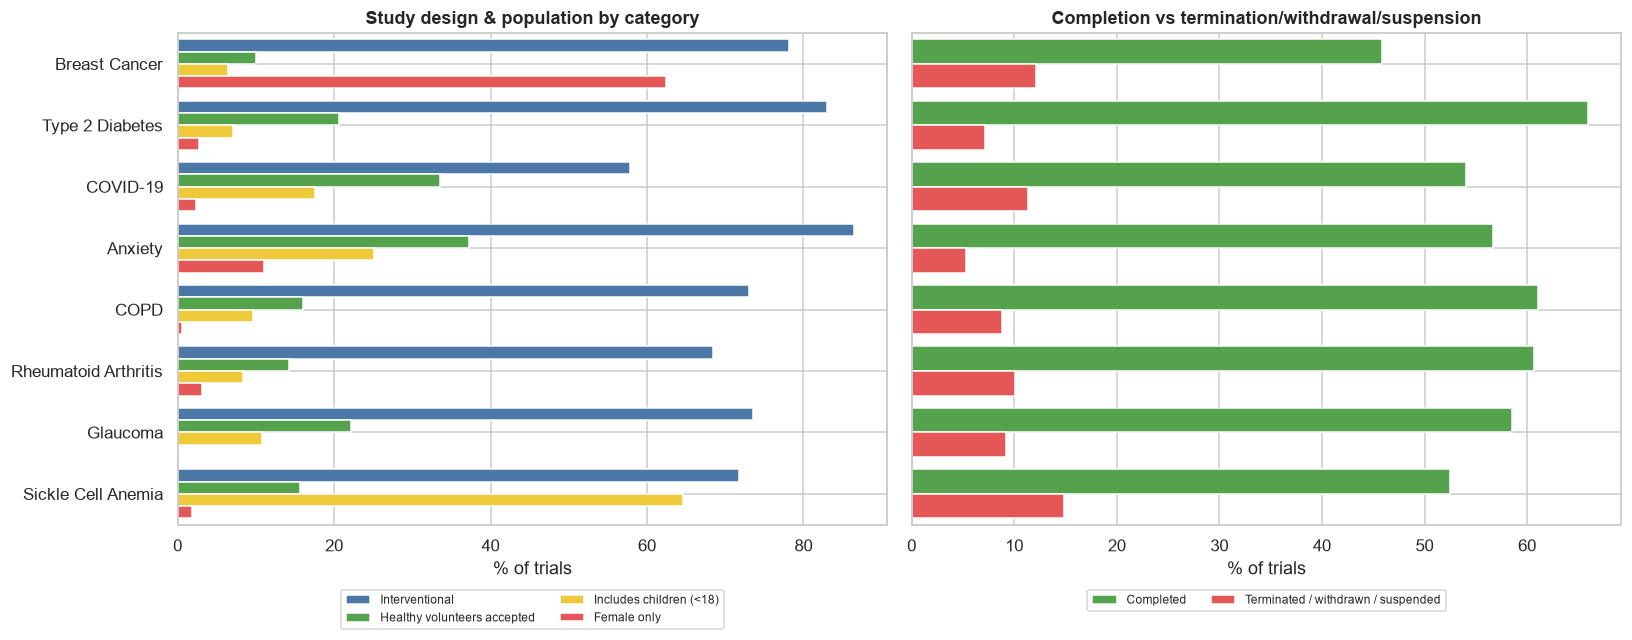

,disease_category,interventional_pct,female_only_pct,healthy_volunteers_pct,includes_children_pct,completed_pct,terminated_or_withdrawn_pct,median_min_age,median_interventions
0,Breast Cancer,78.1,62.4,10.0,6.4,45.9,12.1,18.0,2.0
1,Type 2 Diabetes,83.0,2.7,20.6,7.1,65.9,7.2,18.0,2.0
2,COVID-19,57.8,2.4,33.5,17.6,54.0,11.3,18.0,1.0
3,Anxiety,86.4,11.1,37.2,25.1,56.7,5.3,18.0,1.0
4,COPD,73.1,0.5,16.0,9.6,61.1,8.8,20.0,1.0
5,Rheumatoid Arthritis,68.4,3.1,14.2,8.3,60.7,10.1,18.0,1.0
6,Glaucoma,73.6,0.0,22.2,10.8,58.5,9.2,18.0,1.0
7,Sickle Cell Anemia,71.8,1.9,15.6,64.6,52.5,14.9,12.0,1.0


In [16]:
display(Image(C.FIGURES_DIR / 'eda_07_design_population.png'))
pd.read_csv(C.TABLES_DIR / 'trial_design_by_category.csv')

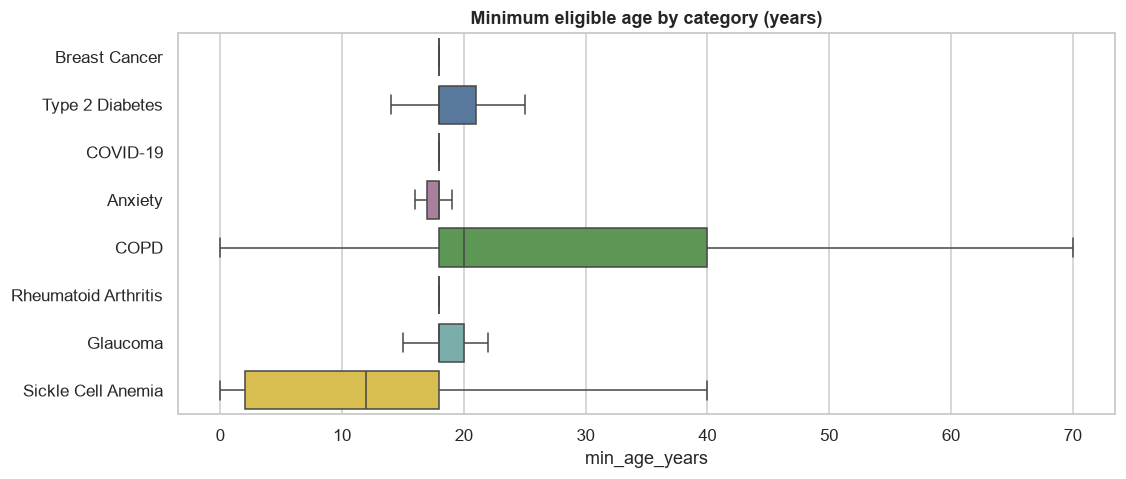

In [17]:
display(Image(C.FIGURES_DIR / 'eda_08_min_age.png'))

### Relationship between summary text and category

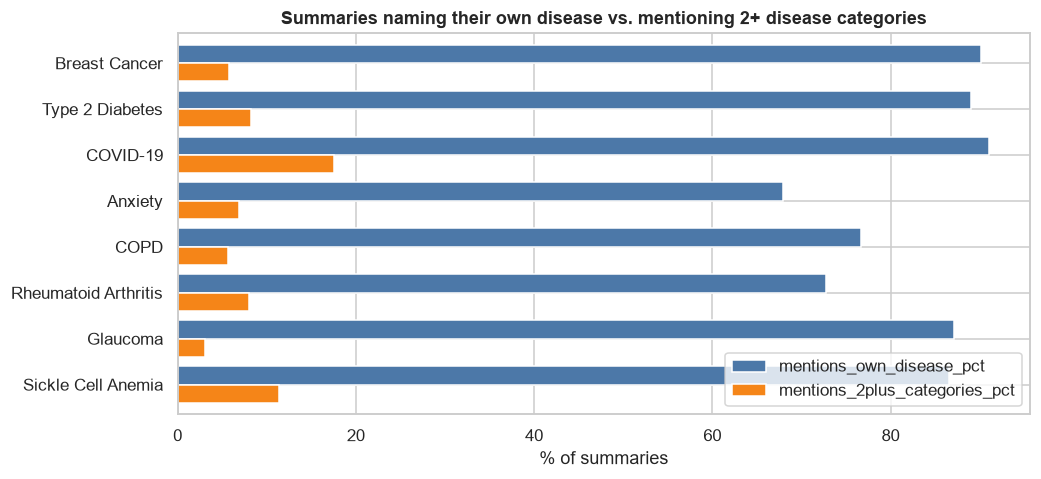

,disease_category,mentions_own_disease_pct,mentions_2plus_categories_pct
0,Breast Cancer,90.1,5.8
1,Type 2 Diabetes,89.0,8.2
2,COVID-19,91.1,17.6
3,Anxiety,67.9,6.9
4,COPD,76.7,5.6
5,Rheumatoid Arthritis,72.7,8.0
6,Glaucoma,87.1,3.1
7,Sickle Cell Anemia,86.5,11.4


In [18]:
display(Image(C.FIGURES_DIR / 'eda_09_disease_mentions.png'))
pd.read_csv(C.TABLES_DIR / 'disease_keyword_mentions.csv')

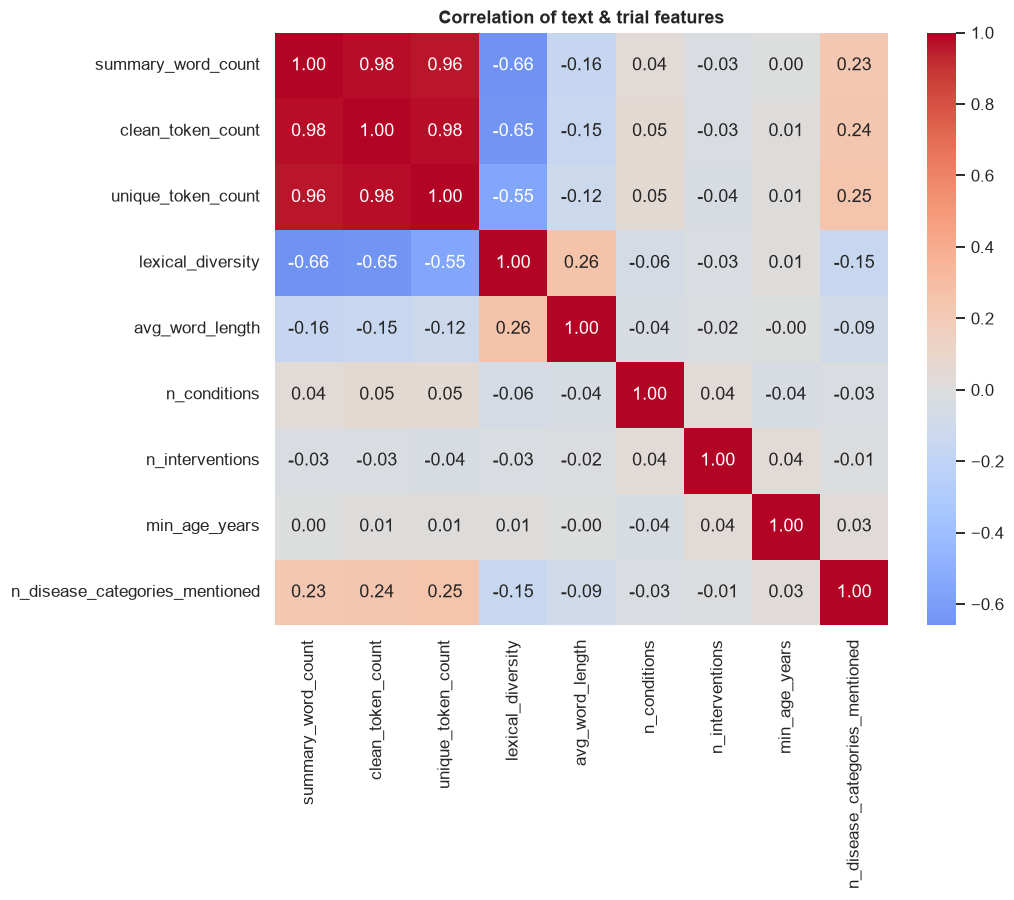

In [19]:
display(Image(C.FIGURES_DIR / 'eda_10_feature_correlation.png'))

## 5. TF-IDF vectorization & feature engineering
Unigrams + bigrams, sub-linear TF, `min_df`/`max_df` filtering. The tuned settings are stored in the model.

In [20]:
meta = json.loads(C.METADATA_PATH.read_text())
print(meta['best_params'])
model = joblib.load(C.MODEL_PATH)
print(model)
X = model.named_steps['tfidf'].transform(feat.clean_text.head(5))
print('TF-IDF matrix for 5 summaries:', X.shape, '| non-zero:', X.nnz)

{'tfidf__ngram_range': [1, 2], 'tfidf__min_df': 3, 'clf__class_weight': None, 'clf__C': 0.6}


Pipeline(steps=[('preprocess', TextPreprocessor()),
                ('tfidf',
                 TfidfVectorizer(dtype=<class 'numpy.float32'>, max_df=0.9,
                                 max_features=60000, min_df=3,
                                 ngram_range=(1, 2), sublinear_tf=True,
                                 token_pattern='(?u)\\b[\\w\\-]+\\b')),
                ('clf',
                 CalibratedClassifierCV(cv=3, estimator=LinearSVC(C=0.6)))])
TF-IDF matrix for 5 summaries: (5, 60000) | non-zero: 235


## 6. Model comparison & evaluation
Six classifiers (Multinomial NB, Complement NB, Logistic Regression, Linear SVM, SGD, Random Forest) tuned with `RandomizedSearchCV` (3-fold stratified CV, macro-F1). The best by CV score is evaluated on the 20% hold-out set.

In [21]:
pd.read_csv(C.REPORTS_DIR / 'model_comparison.csv').drop(columns='best_params')

,model,cv_f1_macro,cv_f1_std,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_precision_weighted,test_recall_weighted,test_f1_weighted,test_roc_auc_ovr_macro,tuning_seconds
0,Linear SVM,0.9472,0.0023,0.9579,0.9625,0.9471,0.9544,0.9583,0.9579,0.9579,0.9969,81.2
1,SGD (modified Huber),0.9460,0.0010,0.9574,0.9547,0.9514,0.9529,0.9581,0.9574,0.9576,0.9959,69.2
2,Logistic Regression,0.9442,0.0023,0.9563,0.9561,0.9488,0.9523,0.9567,0.9563,0.9564,0.9977,161.6
3,Random Forest,0.9363,0.0026,0.9457,0.9585,0.9268,0.9414,0.9469,0.9457,0.9456,0.9957,662.5
4,Complement Naive Bayes,0.9329,0.0014,0.9449,0.9498,0.9360,0.9421,0.9466,0.9449,0.9451,0.9957,58.4
5,Multinomial Naive Bayes,0.9065,0.0019,0.9232,0.9274,0.9121,0.9185,0.9273,0.9232,0.9239,0.9933,67.5


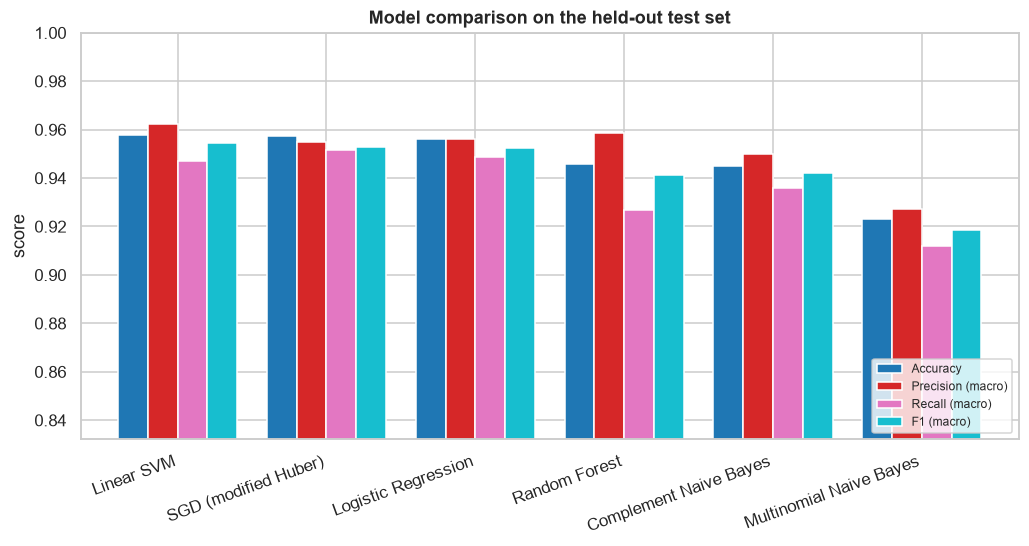

In [22]:
display(Image(C.FIGURES_DIR / 'model_01_comparison.png'))

In [23]:
print(meta['best_model'], meta['test_metrics'])
pd.read_csv(C.REPORTS_DIR / 'classification_report.csv', index_col=0)

Linear SVM {'accuracy': 0.9586, 'precision_macro': 0.9619, 'recall_macro': 0.9485, 'f1_macro': 0.9549, 'precision_weighted': 0.9589, 'recall_weighted': 0.9586, 'f1_weighted': 0.9586, 'roc_auc_ovr_macro': 0.9978}


,precision,recall,f1-score,support
Breast Cancer,0.9689,0.9760,0.9724,3251.0000
Type 2 Diabetes,0.9597,0.9728,0.9662,2277.0000
COVID-19,0.9737,0.9525,0.9630,2020.0000
Anxiety,0.9241,0.9541,0.9389,1851.0000
COPD,0.9400,0.9315,0.9357,1227.0000
Rheumatoid Arthritis,0.9708,0.9197,0.9445,722.0000
Glaucoma,0.9857,0.9651,0.9753,430.0000
Sickle Cell Anemia,0.9720,0.9163,0.9433,227.0000
accuracy,0.9586,0.9586,0.9586,0.9586
macro avg,0.9619,0.9485,0.9549,12005.0000


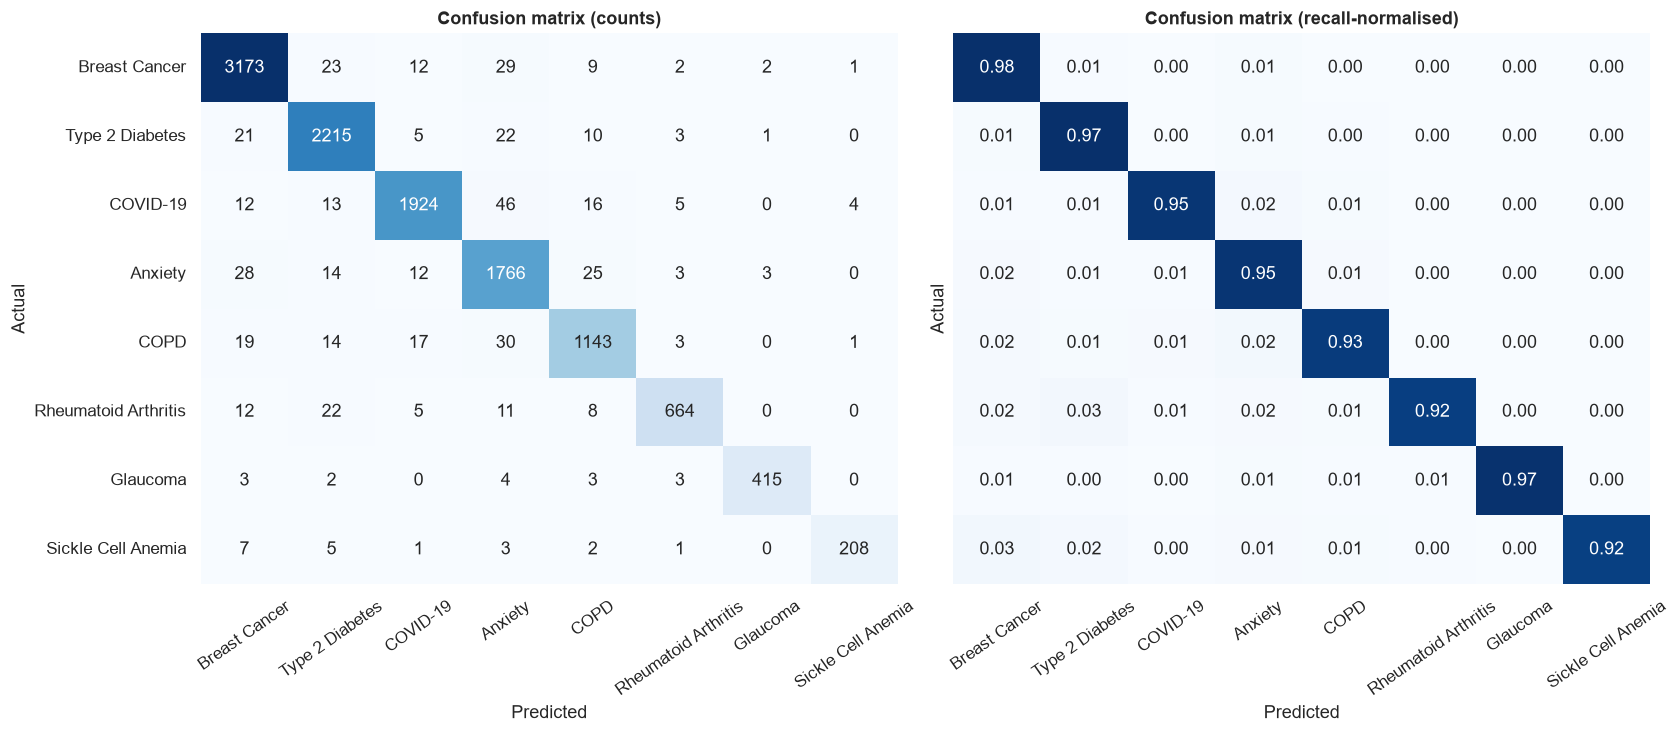

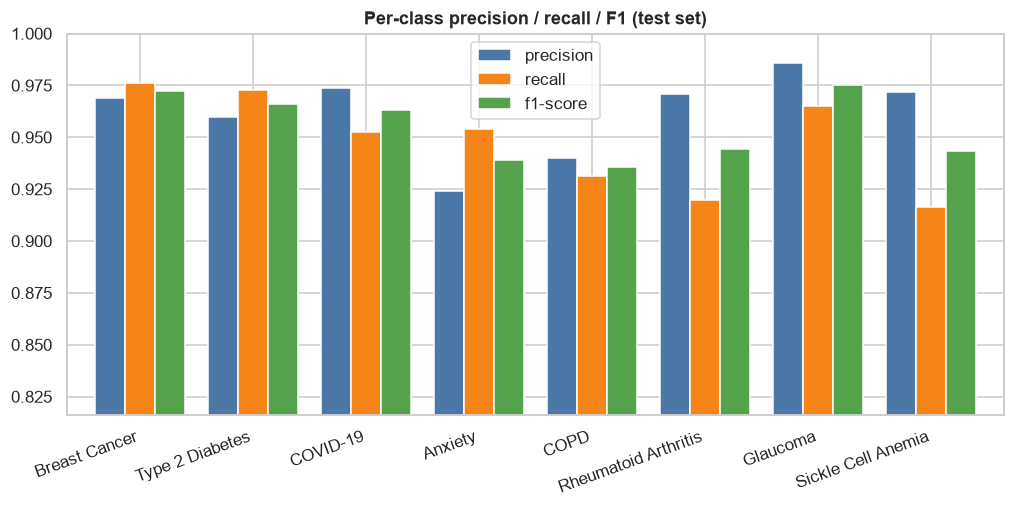

In [24]:
display(Image(C.FIGURES_DIR / 'model_02_confusion_matrix.png'))
display(Image(C.FIGURES_DIR / 'model_03_per_class_metrics.png'))

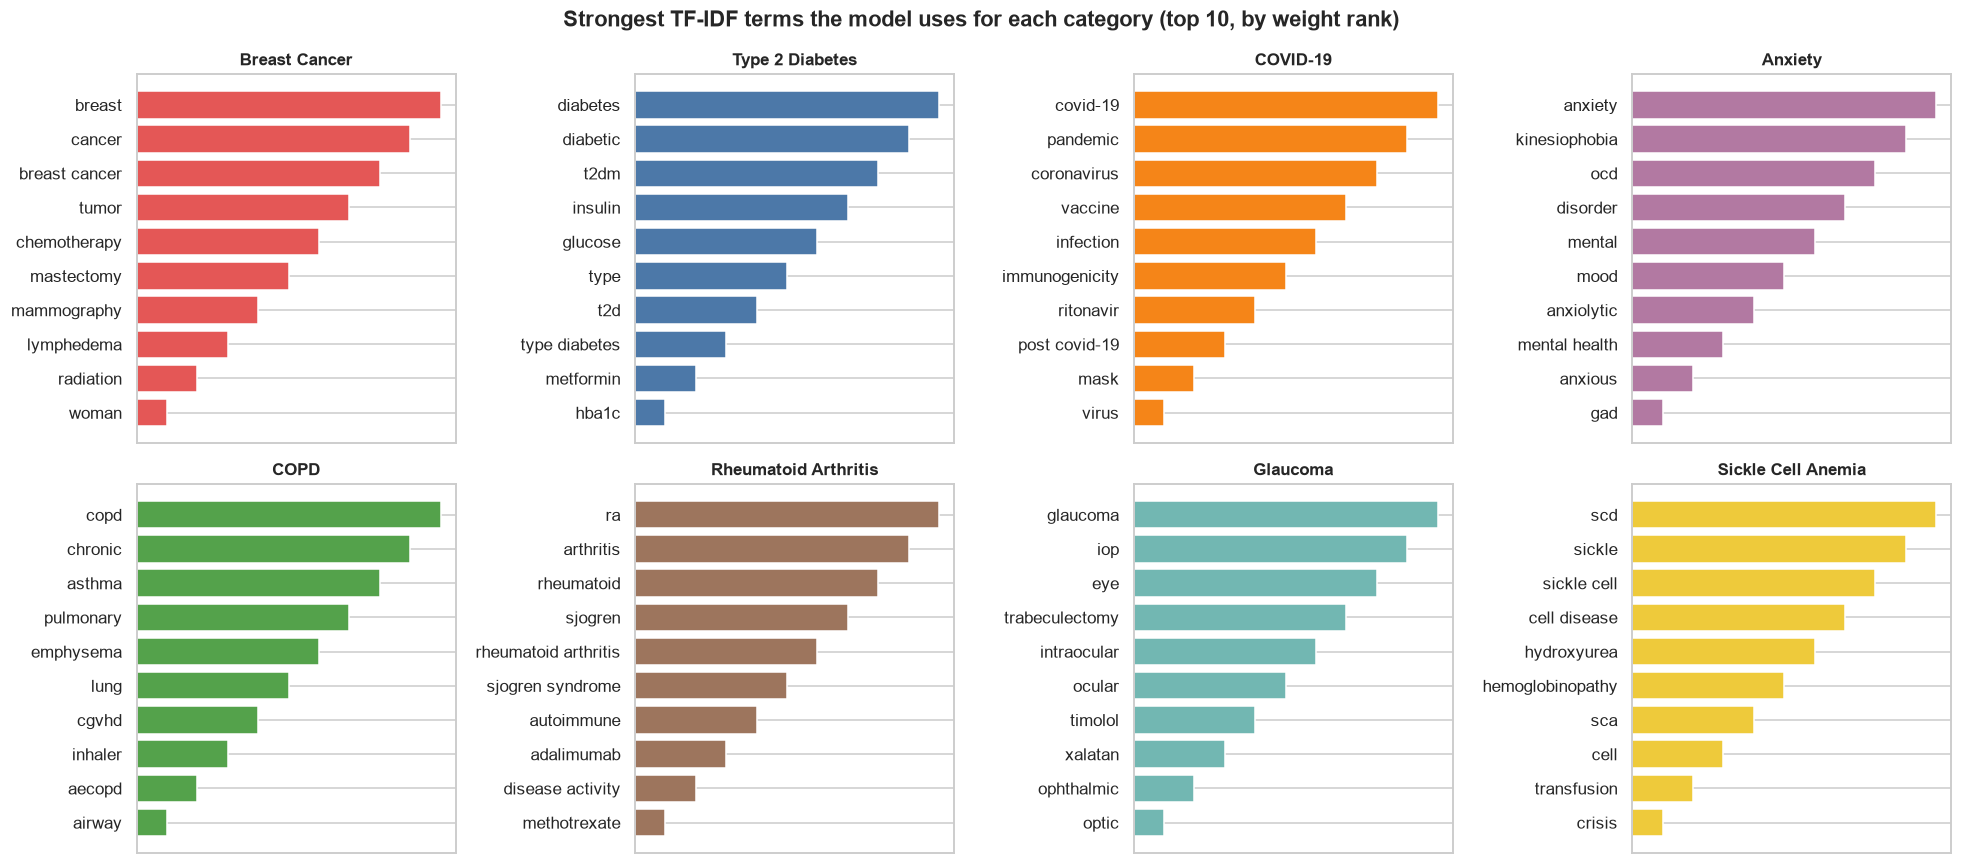

In [25]:
display(Image(C.FIGURES_DIR / 'model_04_top_terms_per_class.png'))

### Robustness & leakage check
Disease-name keywords are removed from train and test text and the model is retrained: if accuracy stayed high only because summaries name the disease, it would collapse.

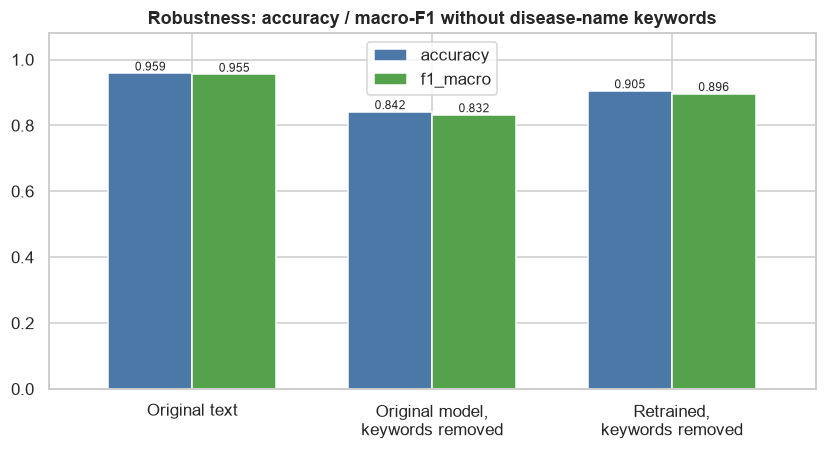

{'original_test': {'accuracy': 0.9586, 'f1_macro': 0.9549},
 'original_model_on_masked_test': {'accuracy': 0.8416, 'f1_macro': 0.8322},
 'retrained_on_masked_text': {'accuracy': 0.9049, 'f1_macro': 0.8964}}

In [26]:
display(Image(C.FIGURES_DIR / 'model_05_keyword_masking.png'))
meta['robustness_keyword_masking']

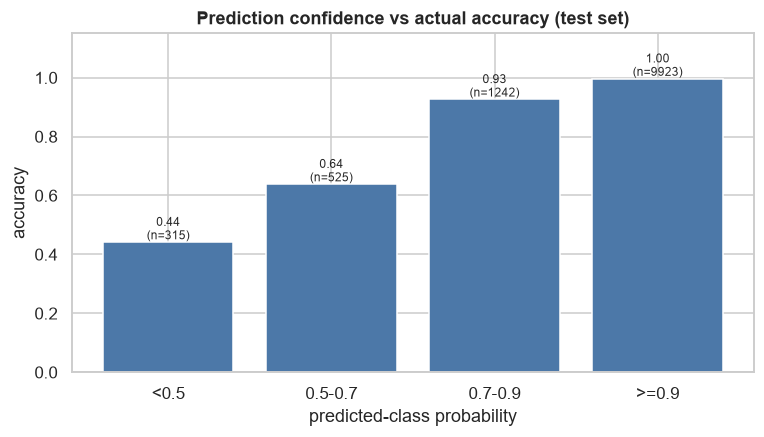

,true,predicted,count
0,COVID-19,Anxiety,46
1,COPD,Anxiety,30
2,Breast Cancer,Anxiety,29
3,Anxiety,Breast Cancer,28
4,Anxiety,COPD,25
5,Breast Cancer,Type 2 Diabetes,23
6,Rheumatoid Arthritis,Type 2 Diabetes,22
7,Type 2 Diabetes,Anxiety,22
8,Type 2 Diabetes,Breast Cancer,21
9,COPD,Breast Cancer,19


In [27]:
display(Image(C.FIGURES_DIR / 'model_06_confidence_accuracy.png'))
pd.read_csv(C.REPORTS_DIR / 'top_confusions.csv')

## 7. Prediction with the saved end-to-end pipeline
Raw text in ➜ category out (same code as the Streamlit app).

In [28]:
samples = [
    'This study evaluates whether adding empagliflozin to metformin improves HbA1c and weight in adults.',
    'A phase 3 trial of trastuzumab deruxtecan versus chemotherapy in HER2-low metastatic disease.',
    'Virtual reality distraction to reduce pre-operative worry and fear in children before surgery.',
    'Hydroxyurea dose escalation to reduce vaso-occlusive pain crises in children with HbSS.',
]
proba = model.predict_proba(samples)
pd.DataFrame({'summary': samples, 'predicted': model.classes_[proba.argmax(1)], 'confidence': proba.max(1).round(3)})

,summary,predicted,confidence
0,This study evaluates whether adding empagliflozin to metformin improves HbA1c and weight in adults.,Type 2 Diabetes,0.979
1,A phase 3 trial of trastuzumab deruxtecan versus chemotherapy in HER2-low metastatic disease.,Breast Cancer,0.981
2,Virtual reality distraction to reduce pre-operative worry and fear in children before surgery.,Anxiety,0.980
3,Hydroxyurea dose escalation to reduce vaso-occlusive pain crises in children with HbSS.,Sickle Cell Anemia,0.941


## 8. Key insights
See `reports/EDA_Report.md` and `reports/Model_Evaluation_Report.md`, and the **Insights** page of the Streamlit app for findings computed live.